### Finite-size scaling of oscillation strength

This notebook analyzes the dependence of oscillation strength on network size for two external input levels, $\nu_{\mathrm{ext}}/\nu_\theta = 0.85$ and $1.4$, at fixed $g=3.159$. The simulations were performed separately, with results stored in the folders `Results_0.85_g3.159` and `Results_1.4_g3.159`. The notebook loads the precomputed summary files `FiniteSize_peakcentered_nu0.85_g3.159.mat` and `FiniteSize_peakcentered_nu1.4_g3.159.mat` and plots the mean oscillation strength as a function of the total number of neurons $N$, with error bars indicating the standard deviation across independent realizations. To assess finite-size scaling, the oscillation strength is fitted to $A_{\mathrm{osc}} = a/\sqrt{N} + b$, where $b$ estimates the oscillation amplitude in the infinite-size limit. The 95% confidence intervals for $b$ are estimated using 20,000 bootstrap resamples of independent realizations within each network size. The notebook generates figures of oscillation strength versus $N$ and versus $1/\sqrt{N}$, including the fitted scaling curves.

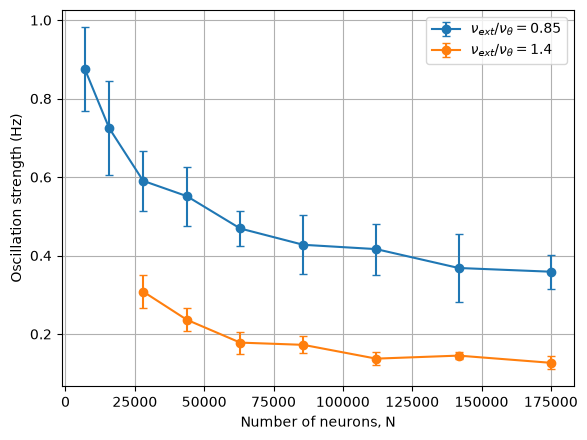

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

# Finite-size fits use only the large-system regime.  The bootstrap
# resamples independent seeds within each system size.
FIT_START_INDEX = 0
N_BOOTSTRAP = 20_000
CONFIDENCE_LEVEL = 0.95
RNG_SEED = 20260924

# ------------------------------------------------------------
# Load results
# ------------------------------------------------------------


data_085 = loadmat("FiniteSize_peakcentered_nu0.85_g3.159.mat")
data_140 = loadmat("FiniteSize_peakcentered_nu1.4_g3.159.mat")

N_085 = np.asarray(data_085["N_total"]).squeeze()
mean_085 = np.asarray(data_085["mean_osc_strength"]).squeeze()
std_085 = np.asarray(data_085["std_osc_strength"]).squeeze()
osc_strength_085 = np.asarray(data_085["osc_strength"], dtype=float)

N_140 = np.asarray(data_140["N_total"]).squeeze()
mean_140 = np.asarray(data_140["mean_osc_strength"]).squeeze()
std_140 = np.asarray(data_140["std_osc_strength"]).squeeze()
osc_strength_140 = np.asarray(data_140["osc_strength"], dtype=float)

x_085 = 1.0 / np.sqrt(N_085)
x_140 = 1.0 / np.sqrt(N_140)


N_085 = N_085[FIT_START_INDEX:]
mean_085 = mean_085[FIT_START_INDEX:]
std_085 = std_085[FIT_START_INDEX:]
osc_strength_085 = osc_strength_085[FIT_START_INDEX:, :]

N_140 = N_140[FIT_START_INDEX:]
mean_140 = mean_140[FIT_START_INDEX:]
std_140 = std_140[FIT_START_INDEX:]
osc_strength_140 = osc_strength_140[FIT_START_INDEX:, :]

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(6, 4.5))

plt.errorbar(
    N_085,
    mean_085,
    yerr=std_085,
    fmt="o-",
    capsize=3,
    label=r"$\nu_{ext}/\nu_\theta = 0.85$",
)

plt.errorbar(
    N_140,
    mean_140,
    yerr=std_140,
    fmt="o-",
    capsize=3,
    label=r"$\nu_{ext}/\nu_\theta = 1.4$",
)

plt.xlabel("Number of neurons, N")
plt.ylabel("Oscillation strength (Hz)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

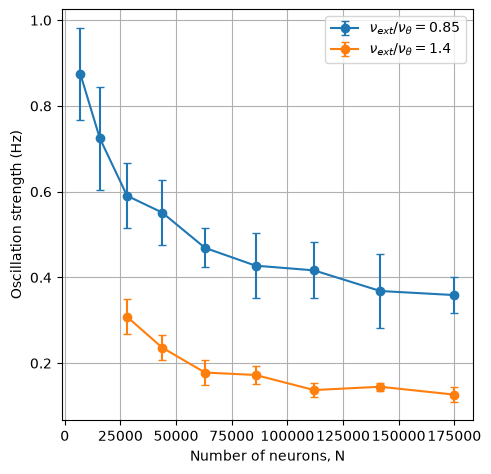

0.85: b = 0.248 Hz; 95% bootstrap CI = [0.206, 0.2892] Hz
1.4: b = -0.0003061 Hz; 95% bootstrap CI = [-0.02627, 0.02677] Hz


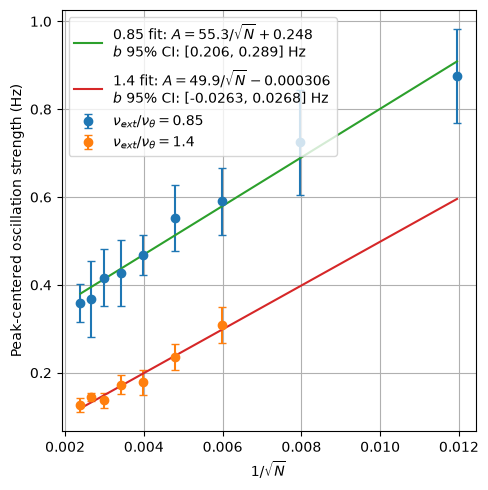

In [2]:
# ------------------------------------------------------------
# Figure 1: Oscillation strength vs N
# ------------------------------------------------------------
x_085 = 1.0 / np.sqrt(N_085)
x_140 = 1.0 / np.sqrt(N_140)

fig1, ax1 = plt.subplots(figsize=(5, 5))

ax1.errorbar(
    N_085,
    mean_085,
    yerr=std_085,
    fmt="o-",
    capsize=3,
    label=r"$\nu_{ext}/\nu_\theta = 0.85$",
)

ax1.errorbar(
    N_140,
    mean_140,
    yerr=std_140,
    fmt="o-",
    capsize=3,
    label=r"$\nu_{ext}/\nu_\theta = 1.4$",
)

ax1.set_xlabel("Number of neurons, N")
ax1.set_ylabel("Oscillation strength (Hz)")
ax1.grid(True)
ax1.legend()

# Square plotting area
ax1.set_box_aspect(1)

fig1.tight_layout()
fig1.savefig(
    "oscillation_strength_vs_N.svg",
    format="svg",
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Figure 2: Oscillation strength vs 1/sqrt(N)
# ------------------------------------------------------------
 
# ------------------------------------------------------------
# Finite-size scaling: A_osc = a / sqrt(N) + b
# ------------------------------------------------------------

x_085 = 1.0 / np.sqrt(N_085)
x_140 = 1.0 / np.sqrt(N_140)

def fit_with_bootstrap_intercept_ci(
    x,
    y_mean,
    seed_values,
    *,
    n_bootstrap=N_BOOTSTRAP,
    confidence_level=CONFIDENCE_LEVEL,
    rng,
):
    """Fit A_osc = a / sqrt(N) + b and bootstrap the CI of b."""
    x = np.asarray(x, dtype=float)
    y_mean = np.asarray(y_mean, dtype=float)
    seed_values = np.asarray(seed_values, dtype=float)

    if seed_values.ndim != 2 or seed_values.shape[0] != x.size:
        raise ValueError("seed_values must have shape (n_sizes, n_seeds).")
    if y_mean.shape != x.shape:
        raise ValueError("x and y_mean must have the same shape.")

    # Point estimate: the same unweighted fit shown in the figure.
    coefficients = np.polyfit(x, y_mean, 1)

    # Bootstrap independent realizations separately at each system size.
    bootstrap_means = np.empty((n_bootstrap, x.size), dtype=float)
    for i, values_at_size in enumerate(seed_values):
        values_at_size = values_at_size[np.isfinite(values_at_size)]
        if values_at_size.size < 2:
            raise ValueError("At least two valid seeds are required at every size.")
        draw_indices = rng.integers(
            0,
            values_at_size.size,
            size=(n_bootstrap, values_at_size.size),
        )
        bootstrap_means[:, i] = values_at_size[draw_indices].mean(axis=1)

    design = np.column_stack((x, np.ones_like(x)))
    bootstrap_coefficients = np.linalg.lstsq(
        design,
        bootstrap_means.T,
        rcond=None,
    )[0]
    bootstrap_intercepts = bootstrap_coefficients[1]

    alpha = 1.0 - confidence_level
    intercept_ci = np.quantile(
        bootstrap_intercepts,
        [alpha / 2.0, 1.0 - alpha / 2.0],
    )
    return coefficients, intercept_ci


def finite_size_fit_label(drive_label, coefficients, intercept_ci):
    confidence_pct = int(100 * CONFIDENCE_LEVEL)
    slope, intercept = coefficients
    lower, upper = intercept_ci
    return (
        rf"{drive_label} fit: $A={slope:.3g}/\sqrt{{N}}{intercept:+.3g}$"
        "\n"
        rf"$b$ {confidence_pct}% CI: [{lower:.3g}, {upper:.3g}] Hz"
    )


rng = np.random.default_rng(RNG_SEED)
p_085, intercept_ci_085 = fit_with_bootstrap_intercept_ci(
    x_085,
    mean_085,
    osc_strength_085,
    rng=rng,
)
p_140, intercept_ci_140 = fit_with_bootstrap_intercept_ci(
    x_140,
    mean_140,
    osc_strength_140,
    rng=rng,
)

confidence_pct = int(100 * CONFIDENCE_LEVEL)
print(
    f"0.85: b = {p_085[1]:.4g} Hz; {confidence_pct}% bootstrap CI "
    f"= [{intercept_ci_085[0]:.4g}, {intercept_ci_085[1]:.4g}] Hz"
)
print(
    f"1.4: b = {p_140[1]:.4g} Hz; {confidence_pct}% bootstrap CI "
    f"= [{intercept_ci_140[0]:.4g}, {intercept_ci_140[1]:.4g}] Hz"
)

# Smooth x-axis for drawing the fitted lines
x_fit = np.linspace(
    min(x_085.min(), x_140.min()),
    max(x_085.max(), x_140.max()),
    200
)

y_fit_085 = np.polyval(p_085, x_fit)
y_fit_140 = np.polyval(p_140, x_fit)


# ------------------------------------------------------------
# Figure 2: Oscillation strength vs 1/sqrt(N)
# ------------------------------------------------------------

fig2, ax2 = plt.subplots(figsize=(5, 5))

ax2.errorbar(
    x_085,
    mean_085,
    yerr=std_085,
    fmt="o",
    capsize=3,
    label=r"$\nu_{ext}/\nu_\theta = 0.85$",
)

ax2.errorbar(
    x_140,
    mean_140,
    yerr=std_140,
    fmt="o",
    capsize=3,
    label=r"$\nu_{ext}/\nu_\theta = 1.4$",
)

ax2.plot(
    x_fit,
    y_fit_085,
    "-",
    label=finite_size_fit_label("0.85", p_085, intercept_ci_085),
)

ax2.plot(
    x_fit,
    y_fit_140,
    "-",
    label=finite_size_fit_label("1.4", p_140, intercept_ci_140),
)

ax2.set_xlabel(r"$1/\sqrt{N}$")
ax2.set_ylabel("Peak-centered oscillation strength (Hz)")
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

# Square plotting area
ax2.set_box_aspect(1)

fig2.tight_layout()
fig2.savefig(
    "oscillation_strength_vs_sqrtN-1.svg",
    format="svg",
    bbox_inches="tight",
)

plt.show()